# Rottnest resource estimate

Copy this notebook into **any project folder**, open that folder in VS Code, and run it.

**Why this works from any folder**

| What | Where it lives | Why it matters |
|---|---|---|
| Rottnest + its Python | `~/Desktop/rottnest/rottnest_venv/` | Select it as this notebook's **kernel** (top right → *Select Kernel* → *Python Environments* → `rottnest_venv`). That's the only setup step. |
| The bridge for your circuit | `~/Desktop/rottnest/rottnest_helpers.py` | Registered in `rottnest_venv`, so `import rottnest_helpers` works from anywhere. |
| Your project's code | this folder | The notebook's working folder, so you can import your own modules directly. |

Rottnest runs the circuit in separate worker processes, which is why the circuit goes through `rottnest_helpers` instead of being passed directly.

## 1. Check the setup
**Why:** if the kernel is wrong, nothing below will work. Both paths should point into `~/Desktop/rottnest`.

In [1]:
import os, sys
import cirq
import pandas as pd
import matplotlib.pyplot as plt
import rottnest_helpers
from rottnest_helpers import count_cirq_circuit, prepare_circuit

print("Python (kernel):  ", sys.executable)
print("rottnest_helpers: ", rottnest_helpers.__file__)
print("This project:     ", os.getcwd())

Python (kernel):   /Users/soumyasarkar/Desktop/rottnest/rottnest_venv/bin/python
rottnest_helpers:  /Users/soumyasarkar/Desktop/rottnest-quickstart/rottnest_helpers.py
This project:      /Users/soumyasarkar/Desktop/rottnest-quickstart


## 2. Get the circuit from your project
**Why:** Rottnest needs a `cirq.Circuit`. Replace the example below with a call into your own code, for example:

```python
from my_module import build_circuit      # my_module.py in this folder
circuit = build_circuit(...)
```

If your project's code needs extra packages, install them into the same environment: `~/Desktop/rottnest/rottnest_venv/bin/pip install <package>`.

In [2]:
# ---- Replace this example with your project's circuit ----
q = cirq.LineQubit.range(3)
circuit = cirq.Circuit(
    cirq.H.on_each(*q),
    cirq.CNOT(q[0], q[1]),
    cirq.rz(0.3).on(q[1]),
    cirq.CZ(q[1], q[2]) ** 0.25,
    cirq.measure(*q, key="m"),
)
# ----------------------------------------------------------

print(f"{len(circuit.all_qubits())} qubits, {len(list(circuit.all_operations()))} operations")
print(circuit if len(circuit) < 40 else "(circuit too long to print)")

3 qubits, 7 operations
0: ───H───@─────────────────────────M('m')───
          │                         │
1: ───H───X───Rz(0.095π)───@────────M────────
                           │        │
2: ───H────────────────────@^0.25───M────────


## 3. Prepare the circuit for Rottnest
**Why:** Rottnest only understands H, X/Y/Z rotations, Rx/Ry/Rz, T, CNOT and CZ, and it **silently miscounts** other gates (for example, it treats `CZ**0.25` as a full CZ). `prepare_circuit` removes measurements and rewrites only the unsupported gates. `count_cirq_circuit` does this automatically; this cell just shows the result and checks it is the same operation. The check is skipped above 10 qubits because it gets slow.

In [3]:
prepared = prepare_circuit(circuit)
print(f"Rottnest will receive {len(list(prepared.all_operations()))} operations")

n = len(circuit.all_qubits())
if n <= 10:
    original = cirq.Circuit(op for op in circuit.all_operations() if not cirq.is_measurement(op))
    order = sorted(original.all_qubits())
    same = cirq.allclose_up_to_global_phase(
        original.unitary(qubit_order=order), prepared.unitary(qubit_order=order), atol=1e-8)
    print("Same operation as your circuit:", same)
else:
    print(f"Equivalence check skipped ({n} qubits)")

Rottnest will receive 10 operations
Same operation as your circuit: True


## 4. Run Rottnest
**Why:** this is the resource estimate. Rottnest counts the rotations, turns each into T gates (gridsynth), and compiles the circuit onto a chip layout (t_scheduler). Small circuits take a few seconds.

Optional arguments: `layout=...` for a different chip (default: t_scheduler's 20×10 example), `verbose=True` to see Rottnest's log if something fails, `timeout=` in seconds (default 600).

In [4]:
result = count_cirq_circuit(circuit)
hw = result["hardware"]

pd.Series({
    "Rz rotations": result["rz_count"],
    "T gates": result["t_count"],
    "T infidelity": f"{result['t_infidelity']:.2e}",
    "Runtime (tocks)": hw["tocks"]["total"],
    "Magic states made": sum(hw["t_source"].values()),
    "Run time (s)": result["seconds"],
}, dtype=object).to_frame("value")

,value
Rz rotations,4
T gates,131
T infidelity,1.91e-05
Runtime (tocks),1479
Magic states made,131
Run time (s),3.78


## 5. Every parameter Rottnest reports
**Why:** section 4 shows the headline numbers. This section shows **everything** Rottnest returns, as a table and as one chart per group, so you can see where the cost goes. The table is built automatically from the result, so any new fields Rottnest reports appear too. The chart is also saved as `rottnest_parameters.png` in your project folder.

| Group | What it measures |
|---|---|
| Gate counts | Rz rotations, T gates after gridsynth, magic states produced |
| T infidelity | error from approximating the rotations (lower is better) |
| Runtime by stage | clock cycles (tocks) for graph-state prep, Bell in/out, T scheduling, and the total |
| Space-time volume by region | chip area × time used by registers, T factories, routing, idling, memory |
| Magic states by factory | how many T states each factory type produced |
| Run time | how long the estimate took on your Mac |

In [5]:
def flatten(d, prefix=""):
    '''Every numeric value in the result, with names like "hardware / tocks / total".'''
    rows = []
    for key, value in d.items():
        name = f"{prefix}{key}"
        if isinstance(value, dict):
            rows += flatten(value, name + " / ")
        elif isinstance(value, (int, float)) and not isinstance(value, bool):
            rows.append((name, value))
    return rows

all_params = pd.DataFrame(flatten(result), columns=["parameter", "value"]).set_index("parameter")
display(all_params.style.format(lambda v: f"{v:.3g}" if abs(v) < 1e-2 else f"{v:,.0f}" if v == int(v) else f"{v:,.2f}"))

,value
parameter,
rz_count,4
t_count,131
t_infidelity,1.91e-05
hardware / tocks / graph_state,12
hardware / tocks / bell_in,12
hardware / tocks / t_schedule,"1,443"
hardware / tocks / bell_out,12
hardware / tocks / total,"1,479"
hardware / volumes / REGISTER_VOLUME,"8,570"


Chart saved to /Users/soumyasarkar/Desktop/rottnest-quickstart/rottnest_parameters.png


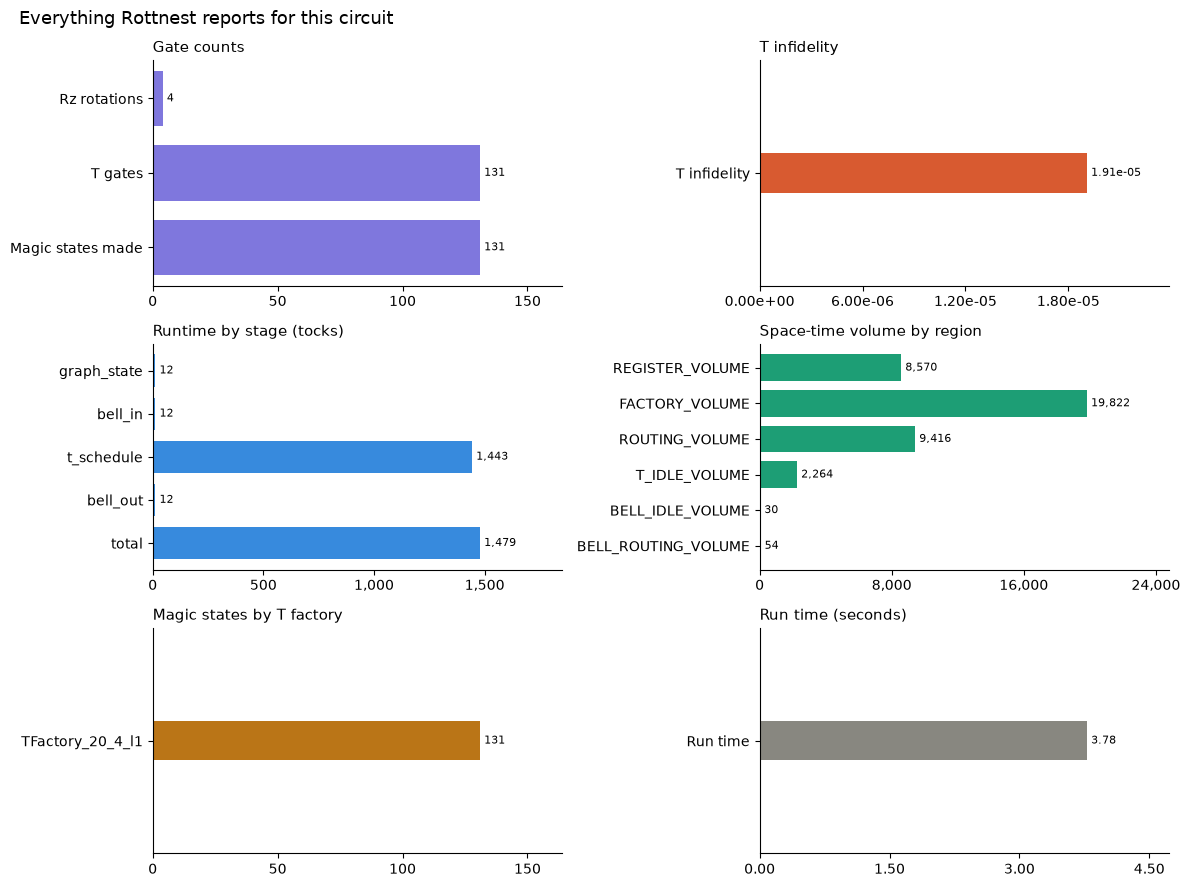

In [6]:
groups = [
    ("Gate counts", {
        "Rz rotations": result["rz_count"],
        "T gates": result["t_count"],
        "Magic states made": sum(hw["t_source"].values()),
    }, "#7F77DD"),
    ("T infidelity", {"T infidelity": result["t_infidelity"]}, "#D85A30"),
    ("Runtime by stage (tocks)", hw["tocks"], "#378ADD"),
    ("Space-time volume by region", hw["volumes"], "#1D9E75"),
    ("Magic states by T factory", hw["t_source"], "#BA7517"),
    ("Run time (seconds)", {"Run time": result["seconds"]}, "#888780"),
]

def fmt(v, biggest):
    '''Scientific notation for tiny numbers, thousands separators for big ones.'''
    if biggest < 1e-2:
        return f"{v:.2e}"
    return f"{v:,.0f}" if biggest >= 10 else f"{v:.2f}"

fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for ax, (title, values, color) in zip(axes.flat, groups):
    names, nums = list(values), list(values.values())
    biggest = max(nums)
    bars = ax.barh(names, nums, color=color, height=0.35 if len(nums) == 1 else 0.75)
    ax.bar_label(bars, labels=[fmt(v, biggest) for v in nums], padding=3, fontsize=8)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlim(0, biggest * 1.25)
    if len(nums) == 1:
        ax.set_ylim(-1, 1)
    ax.invert_yaxis()
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _, b=biggest: fmt(x, b)))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.suptitle("Everything Rottnest reports for this circuit", fontsize=13, x=0.02, ha="left")
plt.tight_layout()
fig.savefig("rottnest_parameters.png", dpi=150, bbox_inches="tight")
print("Chart saved to", os.path.abspath("rottnest_parameters.png"))

## 6. How the cost grows with qubit count
**Why:** one estimate tells you the cost of one circuit; running several sizes tells you how the cost **scales**, which is what matters for larger problems. This section re-runs Rottnest for each size (a few seconds each) and plots every parameter against the number of qubits.

Replace `circuit_for(n)` with your project's circuit for `n` qubits, for example `return build_circuit(n_qubits=n)`. If your circuit has no size parameter, skip this section.

Saved in your project folder: `rottnest_scaling.csv` (all numbers) and `rottnest_scaling.png` (the chart).

In [8]:
# ---- Replace with your project's circuit for n qubits ----
def circuit_for(n):
    return cirq.Circuit(cirq.qft(*cirq.LineQubit.range(n)))

sizes = [2, 3, 4, 5, 6]
# ----------------------------------------------------------

runs = {}
for n in sizes:
    r = count_cirq_circuit(circuit_for(n))
    runs[n] = dict(flatten(r))
    print(f"{n} qubits: {r['t_count']:,} T gates, {r['hardware']['tocks']['total']:,} tocks ({r['seconds']} s)")

# One row per size, one column per parameter (0 where a size didn't report it)
scaling = pd.DataFrame.from_dict(runs, orient="index").fillna(0)
scaling.index.name = "qubits"
scaling.to_csv("rottnest_scaling.csv")
scaling

2 qubits: 3 T gates, 72 tocks (3.45 s)
3 qubits: 120 T gates, 1,450 tocks (3.4 s)
4 qubits: 345 T gates, 3,840 tocks (3.41 s)
5 qubits: 759 T gates, 7,984 tocks (3.5 s)
6 qubits: 1,317 T gates, 13,773 tocks (3.62 s)


,rz_count,t_count,t_infidelity,hardware / tocks / graph_state,hardware / tocks / bell_in,hardware / tocks / t_schedule,hardware / tocks / bell_out,hardware / tocks / total,hardware / volumes / REGISTER_VOLUME,hardware / volumes / FACTORY_VOLUME,hardware / volumes / ROUTING_VOLUME,hardware / volumes / T_IDLE_VOLUME,hardware / volumes / BELL_IDLE_VOLUME,hardware / volumes / BELL_ROUTING_VOLUME,hardware / t_source / TFactory_20_4_l1,seconds
qubits,,,,,,,,,,,,,,,,
2,3,3,0.000833,8,8,48,8,72,309,1166,356,12,10,36,3,3.45
3,9,120,0.000021,38,24,1352,24,1450,6751,18656,9800,2224,60,108,120,3.40
4,18,345,0.000007,80,56,3551,56,3840,26415,51887,28484,5475,190,252,345,3.41
5,30,759,0.000003,138,88,7581,88,7984,63507,113685,59148,10766,380,396,765,3.50
6,45,1317,0.000002,208,132,13101,132,13773,105571,193556,103724,18884,580,594,1317,3.62


Chart saved to /Users/soumyasarkar/Desktop/rottnest-quickstart/rottnest_scaling.png


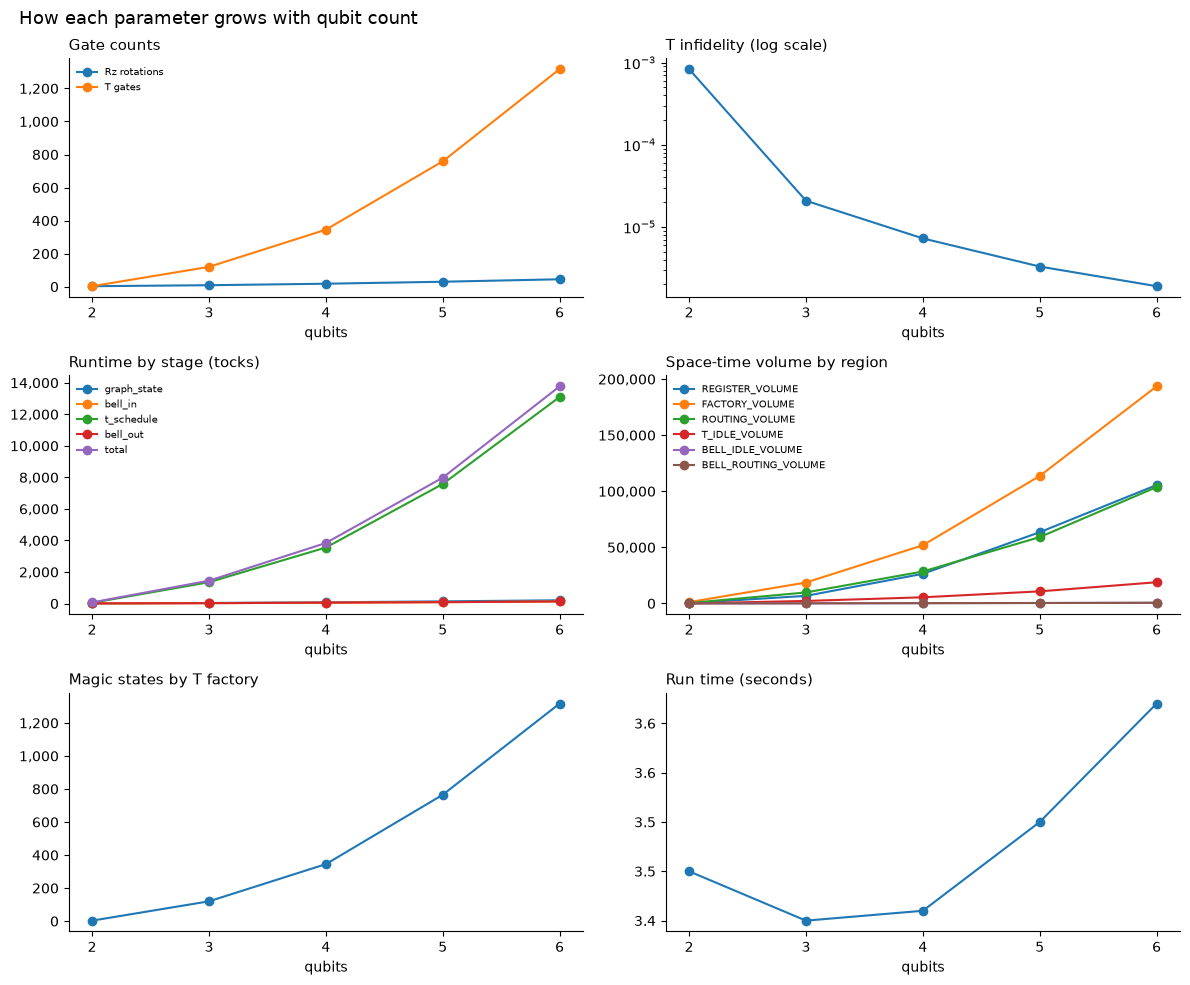

In [9]:
def cols(prefix):
    '''Columns of the scaling table that start with prefix, with short labels.'''
    return {c: c.split(" / ")[-1] for c in scaling.columns if c.startswith(prefix)}

panels = [
    ("Gate counts", {"rz_count": "Rz rotations", "t_count": "T gates"}),
    ("T infidelity (log scale)", {"t_infidelity": "T infidelity"}),
    ("Runtime by stage (tocks)", cols("hardware / tocks / ")),
    ("Space-time volume by region", cols("hardware / volumes / ")),
    ("Magic states by T factory", cols("hardware / t_source / ")),
    ("Run time (seconds)", {"seconds": "Run time"}),
]

def tick(y, _):
    if y == 0:
        return "0"
    return f"{y:.0e}" if abs(y) < 1e-2 else f"{y:,.0f}" if abs(y) >= 10 else f"{y:.1f}"

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, (title, series) in zip(axes.flat, panels):
    for column, name in series.items():
        ax.plot(scaling.index, scaling[column], marker="o", label=name)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xticks(scaling.index)
    ax.set_xlabel("qubits")
    if "log scale" in title:
        ax.set_yscale("log")
    else:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(tick))
    if len(series) > 1:
        ax.legend(fontsize=7, frameon=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.suptitle("How each parameter grows with qubit count", fontsize=13, x=0.02, ha="left")
plt.tight_layout()
fig.savefig("rottnest_scaling.png", dpi=150, bbox_inches="tight")
print("Chart saved to", os.path.abspath("rottnest_scaling.png"))

## 7. Save the result (optional)
**Why:** keeps the numbers with your project, so you can compare runs later.

In [ ]:
import json
with open("rottnest_result.json", "w") as f:
    json.dump(result, f, indent=1)
print("Saved to", os.path.abspath("rottnest_result.json"))